# Learning-rate tuning results

This notebook reads the runs produced by `jobs/tune.sbatch` and helps pick a learning rate.

**What was run:** 3 learning rates × 3 sampling conditions, all at size 1000 and seed 0.
Everything else (steps, batch size, warm-up, ...) was the same for every run.

**Where the results are:**
```
runs_tune/lr<LR>/<condition>_n1000_seed0/run_info.json   settings + final scores
runs_tune/lr<LR>/<condition>_n1000_seed0/dev_curve.csv   dev loss every eval_every steps
```

**What we look at, in order:**
1. A table of the final scores for every run.
2. Which learning rate is best for each condition, and whether it is the same one for all.
3. The dev-loss curves, to check that training behaved sensibly.
4. Whether the step budget was long enough.

In [9]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Paths below are relative to the repository root. If the notebook was started
# from inside notebooks/, move up one level.
if Path.cwd().name == "notebooks":
    os.chdir("..")

TUNE_DIR = Path("runs_tune2")
CONDITIONS = ["uniform", "length", "joint"]  # fixed order for tables and plots

## 1. Load every run

Each run folder has a `run_info.json`. We read them all into one table, one row per run.

In [10]:
rows = []
for info_file in sorted(TUNE_DIR.glob("lr*/*/run_info.json")):
    info = json.loads(info_file.read_text())
    rows.append(
        {
            "condition": info["condition"],
            "lr": info["lr"],
            "best_step": info["best_step"],
            "steps": info["steps"],
            "dev_loss": info["best_dev_loss"],
            "dev_bleu": info["dev_bleu_greedy"],
            "run_dir": info_file.parent,
        }
    )
runs = pd.DataFrame(rows)

print(f"found {len(runs)} of 9 runs")
runs.drop(columns="run_dir")

found 9 of 9 runs


,condition,lr,best_step,steps,dev_loss,dev_bleu
0,joint,0.000010,50,300,2.197826,14.718630
1,length,0.000010,60,300,2.189450,14.637828
2,uniform,0.000010,90,300,2.188196,14.901158
3,joint,0.000003,140,300,2.185880,14.953773
4,length,0.000003,130,300,2.181388,14.872151
5,uniform,0.000003,160,300,2.174034,14.975902
6,joint,0.000005,70,300,2.187108,14.797943
7,length,0.000005,70,300,2.183803,14.743162
8,uniform,0.000005,140,300,2.175757,15.078639


If fewer than 9 runs were found, some tasks are still running or failed.
Check `logs/slurm/mt-tune-*.out` for the missing ones.

## 2. Compare learning rates

Two tables, rows = learning rate, columns = condition:
- **dev BLEU** (higher is better): the metric we actually care about.
- **dev loss** (lower is better): what checkpoint selection used. Mainly a sanity check.

Rough rule of thumb: BLEU differences below about 0.5 are within seed noise, so treat
those learning rates as equally good.

In [12]:
bleu = runs.pivot(index="lr", columns="condition", values="dev_bleu")[CONDITIONS]
loss = runs.pivot(index="lr", columns="condition", values="dev_loss")[CONDITIONS]

# Show learning rates as 1e-05 instead of 0.00001.
print("dev BLEU (higher is better)")
display(bleu.rename(index="{:g}".format).round(2))
print("dev loss (lower is better)")
display(loss.rename(index="{:g}".format).round(4))

dev BLEU (higher is better)


condition,uniform,length,joint
lr,,,
3e-06,14.98,14.87,14.95
5e-06,15.08,14.74,14.80
1e-05,14.90,14.64,14.72


dev loss (lower is better)


condition,uniform,length,joint
lr,,,
3e-06,2.1740,2.1814,2.1859
5e-06,2.1758,2.1838,2.1871
1e-05,2.1882,2.1894,2.1978


In [13]:
# Best learning rate for each condition, by dev BLEU.
best_lr = bleu.idxmax()
print("best learning rate per condition:")
for condition in CONDITIONS:
    print(f"  {condition:8s} lr = {best_lr[condition]:g}  (BLEU {bleu[condition].max():.2f})")

# Average over conditions: the best single learning rate if we use one for everyone.
mean_bleu = bleu.mean(axis=1)
print(f"\nmean BLEU over conditions, per learning rate:")
for lr, value in mean_bleu.items():
    print(f"  lr = {lr:g}: {value:.2f}")

if best_lr.nunique() == 1:
    print(f"\n-> Same best learning rate for every condition: use lr = {best_lr.iloc[0]:g} for all.")
else:
    print(
        "\n-> The best learning rate differs between conditions. Either use each condition's own best,"
        " or check whether one learning rate is within ~0.5 BLEU of the best everywhere and use that."
    )

best learning rate per condition:
  uniform  lr = 5e-06  (BLEU 15.08)
  length   lr = 3e-06  (BLEU 14.87)
  joint    lr = 3e-06  (BLEU 14.95)

mean BLEU over conditions, per learning rate:
  lr = 3e-06: 14.93
  lr = 5e-06: 14.87
  lr = 1e-05: 14.75

-> The best learning rate differs between conditions. Either use each condition's own best, or check whether one learning rate is within ~0.5 BLEU of the best everywhere and use that.


## 3. Dev-loss curves

One panel per condition, one line per learning rate (darker = higher learning rate).
The dot marks the selected checkpoint (lowest dev loss). Step 0 is the pretrained model.

What to look for:
- **Curve goes down, then flattens or rises again:** normal. Rising means overfitting;
  checkpoint selection takes care of it.
- **Curve shoots up right away:** learning rate too high.
- **Curve barely moves:** learning rate too low (or too few steps).

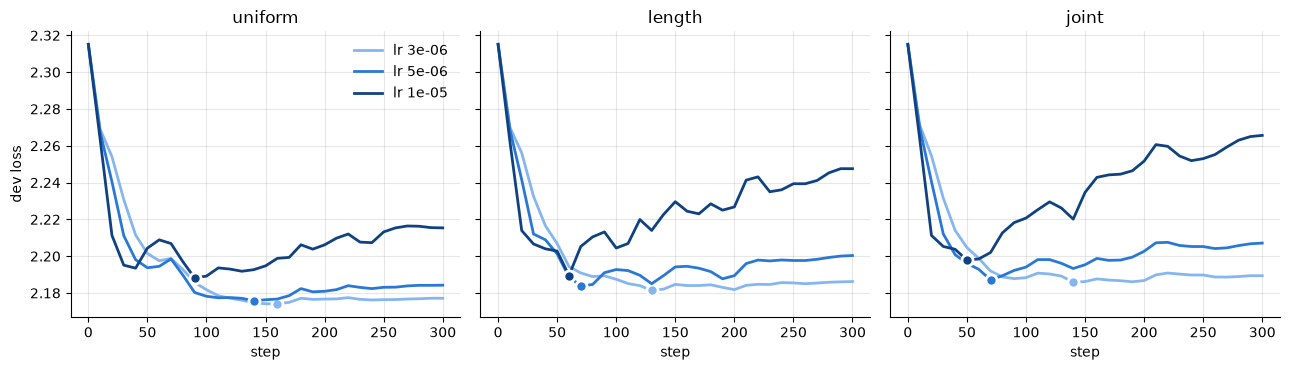

In [14]:
# One blue hue, light -> dark for low -> high learning rate (the learning rates are ordered).
SHADES = ["#86b6ef", "#2a78d6", "#104281"]
lrs = sorted(runs["lr"].unique())
colour = {lr: SHADES[i] for i, lr in enumerate(lrs)}

fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(13, 3.8), sharey=True)
for ax, condition in zip(axes, CONDITIONS):
    for _, run in runs[runs["condition"] == condition].sort_values("lr").iterrows():
        curve = pd.read_csv(run["run_dir"] / "dev_curve.csv")
        ax.plot(curve["step"], curve["dev_loss"], color=colour[run["lr"]], linewidth=2, label=f"lr {run['lr']:g}")
        ax.plot(run["best_step"], run["dev_loss"], "o", color=colour[run["lr"]], markersize=8,
                markeredgecolor="white", markeredgewidth=2)
    ax.set_title(condition)
    ax.set_xlabel("step")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("dev loss")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

## 4. Was the step budget long enough?

If the selected checkpoint is the **last** step, dev loss was still going down when training
stopped, so a longer run might have done better. In that case, increase `--steps` before the
final experiments (or note it as a limitation).

In [15]:
at_end = runs[runs["best_step"] == runs["steps"]]
if at_end.empty:
    print("OK: every run reached its best dev loss before the last step.")
else:
    print("Best checkpoint was the last step for these runs (budget may be too short):")
    display(at_end[["condition", "lr", "best_step", "steps"]])

OK: every run reached its best dev loss before the last step.


## Decision


It would seem that the learning rate of 3e-06 acheives the lowest validation loss for n=1000 and for all of the weighing schemes. 

However, we are not sure this scales to the full dataset so we will do a full sized run on uniform weigths now we know the different schemes seem to agree on the best learning rate.

**To do later:** check that the choice carries over to the full dataset by running the three
learning rates once at `--size full` with `uniform` only.